In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder

In [2]:
data = pd.read_csv("/kaggle/input/datasets/mobeenfatimah/resume-screening-and-ats-hiring-dataset100k-record/ai_resume_screening_dataset.csv")

In [3]:
data.head()

,candidate_id,full_name,email,phone,country,city,age,gender,highest_education,university,...,expected_salary,preferred_location,employment_type,remote_preference,availability,resume_quality_score,resume_length,keyword_match_percentage,ats_score,selected
0,CAND-000001,Allison Hill,allison.hill13@gmail.com,+1-959-381-5012,Burundi,Lake Joyside,35,Female,Master,Georgia Institute of Technology,...,172000,Burundi,Internship,Hybrid,30 Days,72,2,20.00,46,Selected
1,CAND-000002,Javier Johnson,javier.johnson58@gmail.com,+1-299-467-6635,Djibouti,New Jamesside,37,Male,Master,National University of Singapore,...,212000,Djibouti,Contract,Remote,Immediate,77,2,20.68,46,Rejected
2,CAND-000003,Jerry Ramirez,jerry.ramirez58@gmail.com,+1-476-755-4598,Senegal,Lake Roberto,41,Male,Bachelor,Massachusetts Institute of Technology,...,193000,Flexible,Full-Time,On-site,Immediate,58,2,62.55,65,Selected
3,CAND-000004,Daniel Gallagher,daniel.gallagher18@gmail.com,+1-594-490-8668,Bermuda,Davisstad,54,Male,PhD,Imperial College London,...,351000,Davisstad,Contract,Hybrid,Immediate,61,1,28.58,43,Selected
4,CAND-000005,Robert Blair,robert.blair40@hotmail.com,+1-780-180-2403,British Virgin Islands,Millerport,52,Male,PhD,National University of Singapore,...,374000,Millerport,Part-Time,Remote,15 Days,62,1,20.00,46,Selected


In [4]:
def basic_checks(data):
    print("-"*35, "Duplicates", "-"*35)
    print(data.duplicated().sum())
    print("-"*35, "Missing Values", "-"*35)
    print(data.isnull().sum())
    print("-"*35, "Shape", "-"*35)
    print(data.shape)
    print("-"*35, "DataTypes", "-"*35)
    print(data.dtypes)
    print("-"*35, "SummaryStatistics(Categorical)", "-"*35)
    print(display(data.describe(include="object").T))
    print("-"*35, "SummaryStatistics(Numerical)","-"*35 )
    print(display(data.describe().T))

In [5]:
basic_checks(data)

----------------------------------- Duplicates -----------------------------------
0
----------------------------------- Missing Values -----------------------------------
candidate_id                0
full_name                   0
email                       0
phone                       0
country                     0
city                        0
age                         0
gender                      0
highest_education           0
university                  0
field_of_study              0
cgpa                        0
graduation_year             0
experience_years            0
previous_companies          0
current_job_title           0
internship_experience       0
leadership_experience       0
technical_skills            0
programming_languages       0
frameworks                  0
databases                   0
cloud_platform              0
projects_completed          0
github_profile              0
linkedin_profile            0
certifications              0
publications      

,count,unique,top,freq
candidate_id,100000,100000,CAND-099961,1
full_name,100000,71126,Michael Smith,44
email,100000,99727,william.smith22@hotmail.com,3
phone,100000,100000,+1-823-581-8485,1
country,100000,243,Korea,813
city,100000,37950,South Michael,97
gender,100000,3,Male,49112
highest_education,100000,5,Bachelor,54807
university,100000,15,University of Washington,6785
field_of_study,100000,9,Cyber Security,11321


None
----------------------------------- SummaryStatistics(Numerical) -----------------------------------


,count,mean,std,min,25%,50%,75%,max
age,100000.0,37.992810,10.095701,21.0,29.00,38.00,47.00,55.0
cgpa,100000.0,3.248341,0.433409,2.5,2.87,3.25,3.62,4.0
graduation_year,100000.0,2008.946510,10.134017,1989.0,2000.00,2009.00,2018.00,2026.0
experience_years,100000.0,16.055770,10.101397,0.0,7.00,16.00,25.00,35.0
projects_completed,100000.0,6.491180,3.452330,1.0,3.00,6.00,9.00,12.0
publications,100000.0,0.379640,0.744781,0.0,0.00,0.00,0.00,3.0
communication_score,100000.0,69.434840,14.655934,30.0,59.00,69.00,80.00,100.0
problem_solving_score,100000.0,71.413430,13.733492,30.0,62.00,72.00,81.00,100.0
technical_test_score,100000.0,67.329030,15.718161,25.0,57.00,67.00,78.00,100.0
interview_score,100000.0,69.370380,14.655315,30.0,59.00,69.00,80.00,100.0


None


In [6]:
cat_columns = data.select_dtypes(include = 'object').columns.to_list()
cat_columns

['candidate_id',
 'full_name',
 'email',
 'phone',
 'country',
 'city',
 'gender',
 'highest_education',
 'university',
 'field_of_study',
 'previous_companies',
 'current_job_title',
 'internship_experience',
 'leadership_experience',
 'technical_skills',
 'programming_languages',
 'frameworks',
 'databases',
 'cloud_platform',
 'github_profile',
 'linkedin_profile',
 'certifications',
 'job_role',
 'preferred_location',
 'employment_type',
 'remote_preference',
 'availability',
 'selected']

In [7]:
categorical_columns = data.select_dtypes(include="object").columns.to_list()

for col in categorical_columns:
    print("-"*35, col, "-"*35)
    print(data[col].unique())
    print(data[col].nunique())

----------------------------------- candidate_id -----------------------------------
['CAND-000001' 'CAND-000002' 'CAND-000003' ... 'CAND-099998' 'CAND-099999'
 'CAND-100000']
100000
----------------------------------- full_name -----------------------------------
['Allison Hill' 'Javier Johnson' 'Jerry Ramirez' ... 'Robert Dillon'
 'Kelsey Bryant' 'John Ferrell']
71126
----------------------------------- email -----------------------------------
['allison.hill13@gmail.com' 'javier.johnson58@gmail.com'
 'jerry.ramirez58@gmail.com' ... 'andrew.martin22@gmail.com'
 'jacob.avila54@gmail.com' 'brent.smith13@hotmail.com']
99727
----------------------------------- phone -----------------------------------
['+1-959-381-5012' '+1-299-467-6635' '+1-476-755-4598' ...
 '+1-566-875-4585' '+1-508-963-2447' '+1-698-327-2581']
100000
----------------------------------- country -----------------------------------
['Burundi' 'Djibouti' 'Senegal' 'Bermuda' 'British Virgin Islands' 'Congo'
 'North Macedo

In [8]:
cat_columns = data.select_dtypes(include = 'object').columns.to_list()
cat_columns

['candidate_id',
 'full_name',
 'email',
 'phone',
 'country',
 'city',
 'gender',
 'highest_education',
 'university',
 'field_of_study',
 'previous_companies',
 'current_job_title',
 'internship_experience',
 'leadership_experience',
 'technical_skills',
 'programming_languages',
 'frameworks',
 'databases',
 'cloud_platform',
 'github_profile',
 'linkedin_profile',
 'certifications',
 'job_role',
 'preferred_location',
 'employment_type',
 'remote_preference',
 'availability',
 'selected']

# Step 4: EDA


Text(0.5, 1.0, 'Distribution of the target')

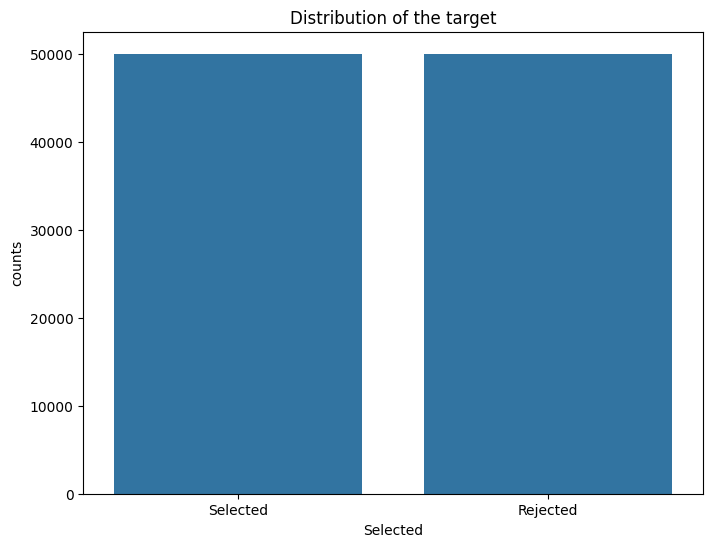

In [9]:
# Distribution of the Target Column
plt.figure(figsize=(8, 6))

sns.countplot(data=data, x='selected')

plt.xlabel("Selected")
plt.ylabel("counts")
plt.title('Distribution of the target')


In [10]:
for column in cat_columns:
    print("-"*40, column,"-"*40)

    H0 = f"No relationship between selected and {column}"
    H1 = f"There is a relationship between between selected and {column}"

    contingency_table =pd.crosstab(data['selected'], data[column])

    stats, p_value, dof, expected = chi2_contingency(contingency_table)

    if p_value <= 0.05:
        
       print(f"Reject the null hypothesis")
    else:
       print(f"Fail to reject the null hypothesis")

---------------------------------------- candidate_id ----------------------------------------
Fail to reject the null hypothesis
---------------------------------------- full_name ----------------------------------------
Fail to reject the null hypothesis
---------------------------------------- email ----------------------------------------
Fail to reject the null hypothesis
---------------------------------------- phone ----------------------------------------
Fail to reject the null hypothesis
---------------------------------------- country ----------------------------------------
Fail to reject the null hypothesis
---------------------------------------- city ----------------------------------------
Fail to reject the null hypothesis
---------------------------------------- gender ----------------------------------------
Fail to reject the null hypothesis
---------------------------------------- highest_education ----------------------------------------
Fail to reject the null hy

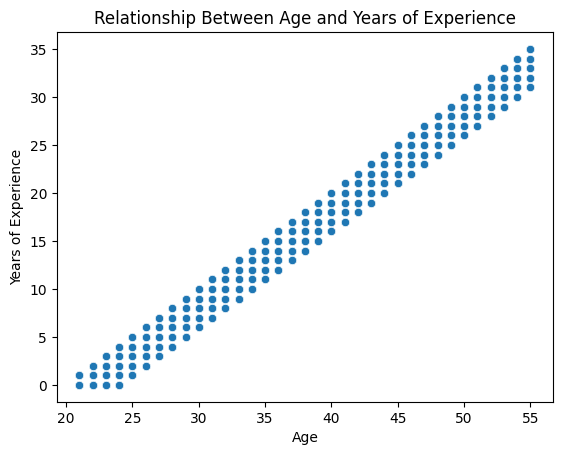

In [11]:
# relationship between a candidates age and their years of experience

sns.scatterplot(
    data=data,
    x='age',
    y='experience_years'
)

plt.title('Relationship Between Age and Years of Experience')
plt.xlabel('Age')
plt.ylabel('Years of Experience')
plt.show()


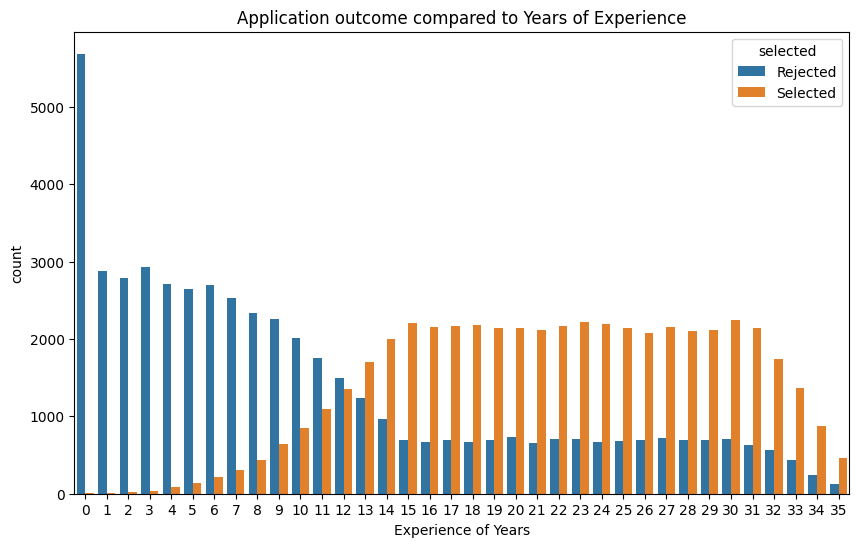

In [12]:
plt.figure(figsize=(10, 6))

sns.countplot(data, x="experience_years", hue="selected")

plt.title('Application outcome compared to Years of Experience')
plt.xlabel('Experience of Years')
plt.show()


In [13]:
education_selection = (
    data.groupby("highest_education")["selected"]
        .apply(lambda x: (x == "Selected").mean() * 100)
        .reset_index(name="selection_rate")
        .sort_values("selection_rate", ascending=False)
)

education_selection

,highest_education,selection_rate
4,PhD,51.298834
1,Diploma,50.748652
2,High School,50.489902
0,Bachelor,49.949824
3,Master,49.464109


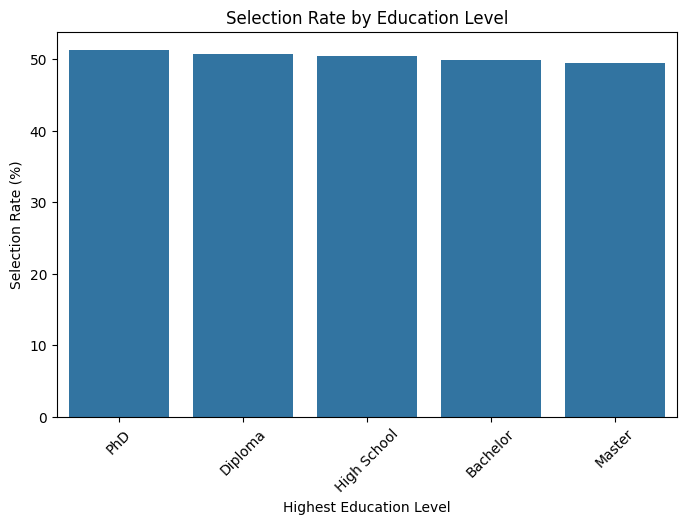

In [14]:
plt.figure(figsize=(8, 5))
 
sns.barplot(
    data=education_selection,
    x='highest_education',
    y='selection_rate'
)
plt.title('Selection Rate by Education Level')
plt.xlabel('Highest Education Level')
plt.ylabel('Selection Rate (%)')
plt.xticks(rotation=45)
plt.show()

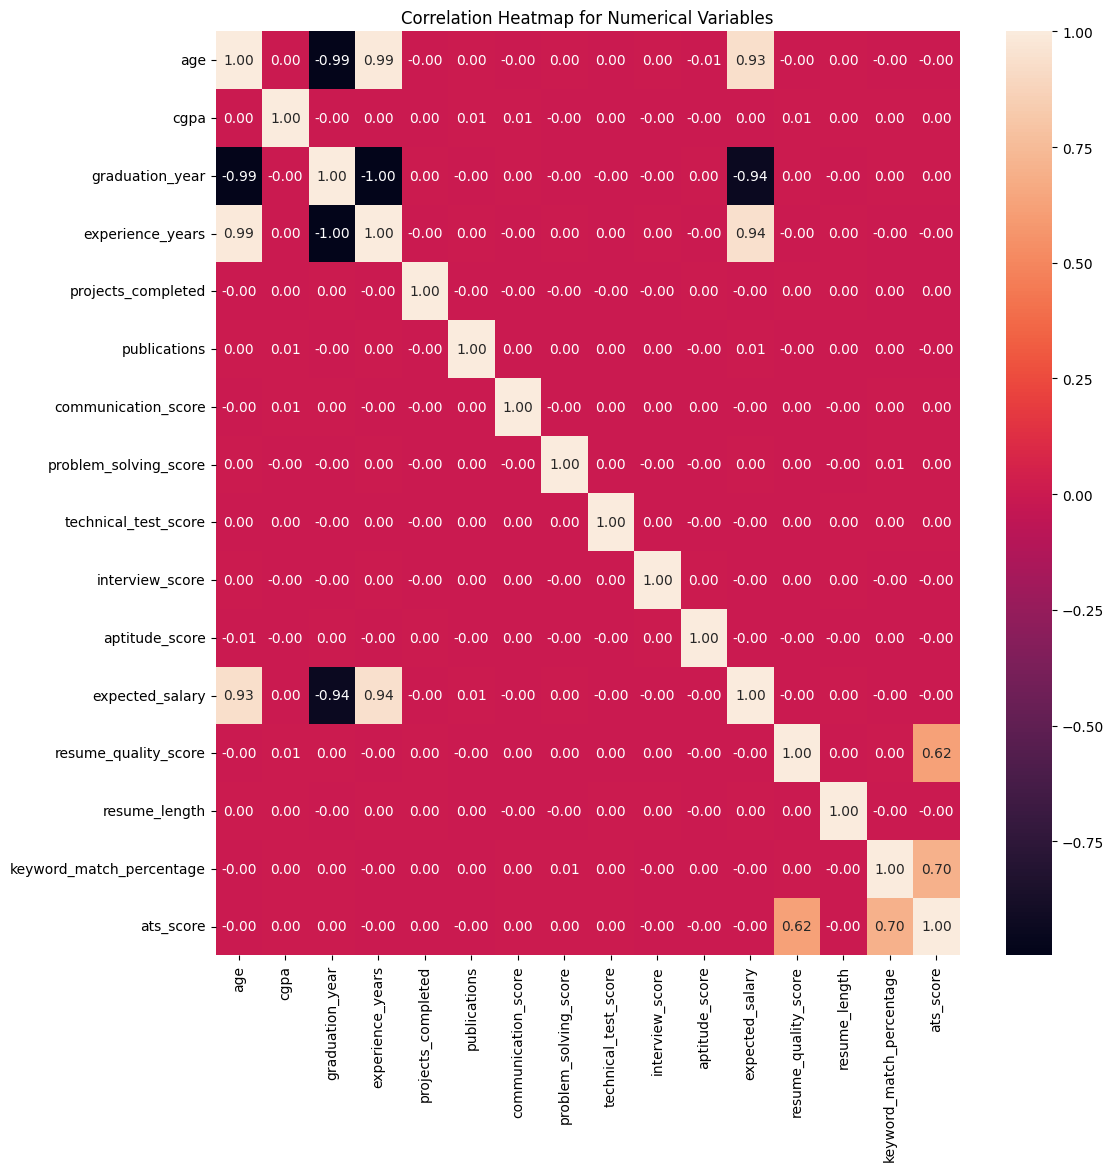

In [15]:
# Correlation between numerical columns
# Select numerical columns
numerical_columns = data.select_dtypes(include='number').columns

# Create correlation table
correlation_table = data[numerical_columns].corr()
plt.figure(figsize=(12, 12))
sns.heatmap(correlation_table, annot=True, fmt=".2f")
plt.title("Correlation Heatmap for Numerical Variables")
plt.show()


In [16]:
X = data.drop(columns= ["candidate_id","full_name","email","phone","country","city","gender","highest_education","university","field_of_study","technical_skills","frameworks","github_profile","linkedin_profile","certifications","job_role","preferred_location","employment_type","remote_preference","availability"])
y = data['selected']

In [17]:
X_train,X_temp, y_train, y_temp = train_test_split(X,y,test_size = 0.30, random_state = 42, stratify = y )

In [18]:
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp,test_size = 0.50, random_state = 42, stratify = y_temp )

In [19]:
numerical_columns = X.select_dtypes(include = ["int", "float"]).columns.to_list()
numerical_columns


['age',
 'cgpa',
 'graduation_year',
 'experience_years',
 'projects_completed',
 'publications',
 'communication_score',
 'problem_solving_score',
 'technical_test_score',
 'interview_score',
 'aptitude_score',
 'expected_salary',
 'resume_quality_score',
 'resume_length',
 'keyword_match_percentage',
 'ats_score']

In [20]:
categorical_columns = X.select_dtypes(include="object").columns.to_list()

print(categorical_columns)

['previous_companies', 'current_job_title', 'internship_experience', 'leadership_experience', 'programming_languages', 'databases', 'cloud_platform', 'selected']


In [21]:
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)
y_val_encoded = le.transform(y_val)


In [22]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [23]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, numerical_columns),
        ("cat", cat_pipeline, categorical_columns)
    ]
)

In [24]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
X_val_processed = preprocessor.transform(X_val)

In [25]:
X_train_processed.shape[1]

26104

In [26]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape = (X_train_processed.shape[1],)),
    tf.keras.layers.Dense(64,activation = "relu"),
    tf.keras.layers.Dense(32, activation = "relu"),
    tf.keras.layers.Dense(32, activation = "relu"),
    tf.keras.layers.Dense(3, activation= "softmax")
])


I0000 00:00:1789366269.355046      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1789366269.357948      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [27]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [28]:
callbacks = tf.keras.callbacks.EarlyStopping(monitor = "val_loss", patience = 5, restore_best_weights = True)

In [29]:
history = model.fit(
    X_train_processed,
    y_train_encoded,
    validation_data=(X_val_processed, y_val_encoded),
    epochs=200,
    batch_size=32,
    callbacks = [callbacks]
)

Epoch 1/200
  58/2188 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7319 - loss: 0.9240    

I0000 00:00:1789366273.842759     134 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


2188/2188 ━━━━━━━━━━━━━━━━━━━━ 15s 6ms/step - accuracy: 0.9958 - loss: 0.0192 - val_accuracy: 1.0000 - val_loss: 3.0813e-06
Epoch 2/200
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 1.0000 - loss: 1.1788e-06 - val_accuracy: 1.0000 - val_loss: 6.0126e-07
Epoch 3/200
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 1.0000 - loss: 2.4201e-07 - val_accuracy: 1.0000 - val_loss: 1.4955e-07
Epoch 4/200
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 1.0000 - loss: 5.6032e-08 - val_accuracy: 1.0000 - val_loss: 3.8449e-08
Epoch 5/200
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 1.0000 - loss: 1.1972e-08 - val_accuracy: 1.0000 - val_loss: 1.0316e-08
Epoch 6/200
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 1.0000 - loss: 2.1492e-09 - val_accuracy: 1.0000 - val_loss: 2.7577e-09
Epoch 7/200
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 1.0000 - loss: 3.6444e-10 - val_accuracy: 1.0000 - val_loss: 7.0731e-10
Epoch 8/200
2188/2188 ━━━━━━━━━━━━━━━━━━━━

In [30]:
print(y.unique(),y_val.unique(), y_test.unique()), y_train.unique()

['Selected' 'Rejected'] ['Selected' 'Rejected'] ['Selected' 'Rejected']


(None, array(['Rejected', 'Selected'], dtype=object))

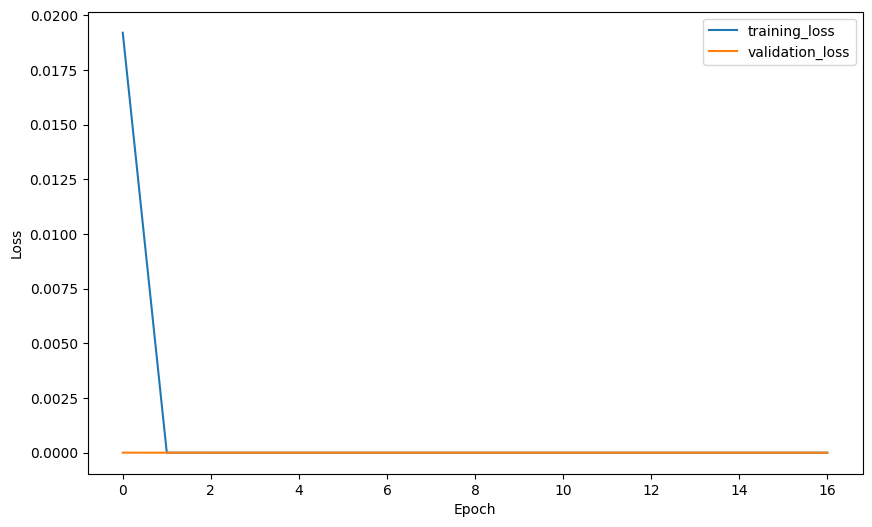

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    history.history["loss"],
    label="training_loss"
)

plt.plot(
    history.history["val_loss"],
    label="validation_loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [32]:
predictions = model.predict(X_test_processed)
y_pred = np.argmax(predictions, axis = 1)


469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step


In [33]:
from sklearn.metrics import classification_report

print(
    "Classification Report:\n",
    classification_report(
        y_test_encoded,
        y_pred,
        target_names=le.classes_
    )
)

Classification Report:
               precision    recall  f1-score   support

    Rejected       1.00      1.00      1.00      7500
    Selected       1.00      1.00      1.00      7500

    accuracy                           1.00     15000
   macro avg       1.00      1.00      1.00     15000
weighted avg       1.00      1.00      1.00     15000



In [34]:
print(y_test_encoded.shape)
print(y_pred.shape)

(15000,)
(15000,)
